# Prostate Patient_1 — pan-cancer Hist2Pheno

Erickson et al. *Nature* 2022. Seven JPEG sections (`H1_2`, `H1_4`, `H1_5`, `H2_1`, `H2_2`, `H2_5`, `V1_2`), StarDist nuclei, **no cell-type ground truth**.
Sample ids are `Patient_1__H1_2`. Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG EXIF is 72 dpi and is not used. µm/px is the HEST-1k spot-spacing estimate, about **0.57–0.69**. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

This notebook is only Patient_1. Patient_2 is `Pred_visual_prostate_patient2.ipynb`. Full-resolution PNGs stay in `data/Visium/Prostate/pred_pancancer_section/figures/`. The cells embed a resized preview so this file does not store the full images.

```bash
SAMPLE=Patient_1 bash code/External_val/Prostate/demo.sh all
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "Prostate"))

from prostate_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
)

PATIENT = "Patient_1"
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Files are written only when SAVE_FIGURES is True.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    section = sample.split("__", 1)[-1]
    print(
        f"{section}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    pth = sample_paths(sample)
    print(f"  pred exists: {pth['pred'].is_file()}  {pth['pred']}")


Patient_1  n=7
H1_2  mpp=0.6876 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3751  (HEST spot-spacing estimate)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_1__H1_2/Patient_1__H1_2_stardist_pred.h5ad
H1_4  mpp=0.5730 µm/px  native16=9.17 µm  after rescale=8.0 µm  scale=1.1459  (HEST spot-spacing estimate)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_1__H1_4/Patient_1__H1_4_stardist_pred.h5ad
H1_5  mpp=0.6876 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3751  (HEST spot-spacing estimate)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/Patient_1__H1_5/Patient_1__H1_5_stardist_pred.h5ad
H2_1  mpp=0.5737 µm/px  native16=9.18 µm  after rescale=8.0 µm  scale=1.1474  (HEST spot-spacing estimate)
  pred exists: True  /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prosta

## Patient_1 — composition and spatial labels


===== Patient_1 L1 =====


fraction                                           mean_conf  \
section         H1_2   H1_4   H1_5   H2_1   H2_2   H2_5   V1_2      H1_2   
class                                                                      
Immune         0.773  0.500  0.685  0.368  0.658  0.651  0.644     0.676   
Endothelial    0.021  0.159  0.095  0.298  0.055  0.062  0.028     0.431   
Stromal        0.186  0.134  0.034  0.125  0.227  0.077  0.283     0.498   
Epithelial     0.021  0.207  0.186  0.207  0.060  0.210  0.045     0.623   
Neural         0.000  0.000  0.000  0.001  0.000  0.000  0.000     0.330   

                           ...                              n            \
section       H1_4   H1_5  ...   H2_2   H2_5   V1_2      H1_2      H1_4   
class                      ...                                            
Immune       0.549  0.590  ...  0.602  0.645  0.642  110274.0  147587.0   
Endothelial  0.446  0.451  ...  0.416  0.465  0.420    2942.0   46870.0   
Stromal      0.457  0.447  ...  0.473  0.465  0.501   26577.0   39710.0   
Epithelial   0.579  0.581  ...  0.575  0.699  0.597    2953.0   61129.0   
Neural       0.326  0.376  ...  0.347  0.367  0.320       2.0      83.0   

                                                              
section          H1_5     H2_1      H2_2      H2_5      V1_2  
class                                                         
Immune       233670.0  65458.0  120543.0  233499.0  104550.0  
Endothelial   32316.0  53033.0    9996.0   22150.0    4546.0  
Stromal       11722.0  22262.0   41484.0   27691.0   45963.0  
Epithelial    63437.0  36827.0   11060.0   75214.0    7288.0  
Neural            2.0    130.0       3.0       7.0       4.0  

[5 rows x 21 columns]

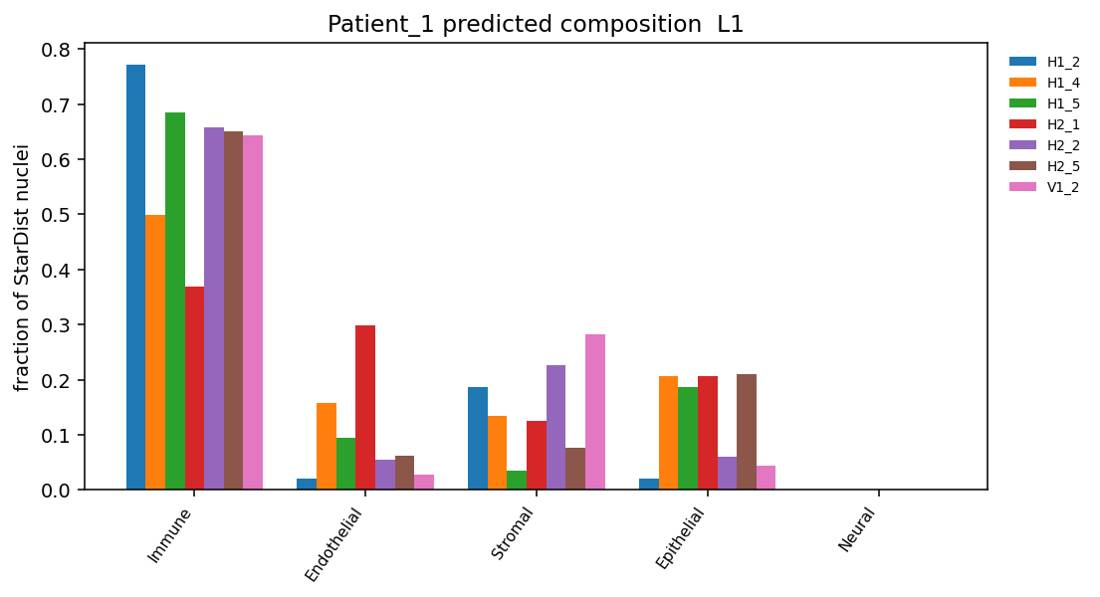

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1_composition_L1.png

===== Patient_1 L12 =====


fraction                                           mean_conf  \
section         H1_2   H1_4   H1_5   H2_1   H2_2   H2_5   V1_2      H1_2   
class                                                                      
T_cell         0.838  0.619  0.836  0.483  0.694  0.697  0.713     0.574   
Stromal        0.127  0.148  0.037  0.173  0.165  0.066  0.194     0.420   
Myeloid        0.018  0.093  0.025  0.176  0.088  0.041  0.033     0.343   
Epithelial     0.007  0.098  0.079  0.046  0.026  0.166  0.007     0.593   
Tumor          0.002  0.025  0.012  0.081  0.017  0.008  0.018     0.430   
Endothelial    0.001  0.017  0.010  0.039  0.003  0.011  0.002     0.319   
B_Plasma       0.007  0.001  0.002  0.002  0.006  0.012  0.033     0.483   

                           ...                              n            \
section       H1_4   H1_5  ...   H2_2   H2_5   V1_2      H1_2      H1_4   
class                      ...                                            
T_cell       0.508  0.558  ...  0.532  0.542  0.538  119600.0  182761.0   
Stromal      0.398  0.379  ...  0.404  0.389  0.419   18062.0   43729.0   
Myeloid      0.340  0.330  ...  0.354  0.370  0.340    2507.0   27324.0   
Epithelial   0.538  0.557  ...  0.580  0.643  0.559    1027.0   28914.0   
Tumor        0.442  0.414  ...  0.439  0.462  0.497     316.0    7259.0   
Endothelial  0.337  0.334  ...  0.318  0.336  0.310     181.0    5123.0   
B_Plasma     0.391  0.406  ...  0.457  0.465  0.520    1055.0     269.0   

                                                              
section          H1_5     H2_1      H2_2      H2_5      V1_2  
class                                                         
T_cell       285155.0  85755.0  127119.0  249748.0  115691.0  
Stromal       12567.0  30678.0   30298.0   23626.0   31557.0  
Myeloid        8542.0  31294.0   16057.0   14550.0    5429.0  
Epithelial    26819.0   8254.0    4842.0   59501.0    1184.0  
Tumor          4033.0  14344.0    3055.0    2925.0    2846.0  
Endothelial    3378.0   7011.0     639.0    3984.0     316.0  
B_Plasma        653.0    374.0    1076.0    4227.0    5328.0  

[7 rows x 21 columns]

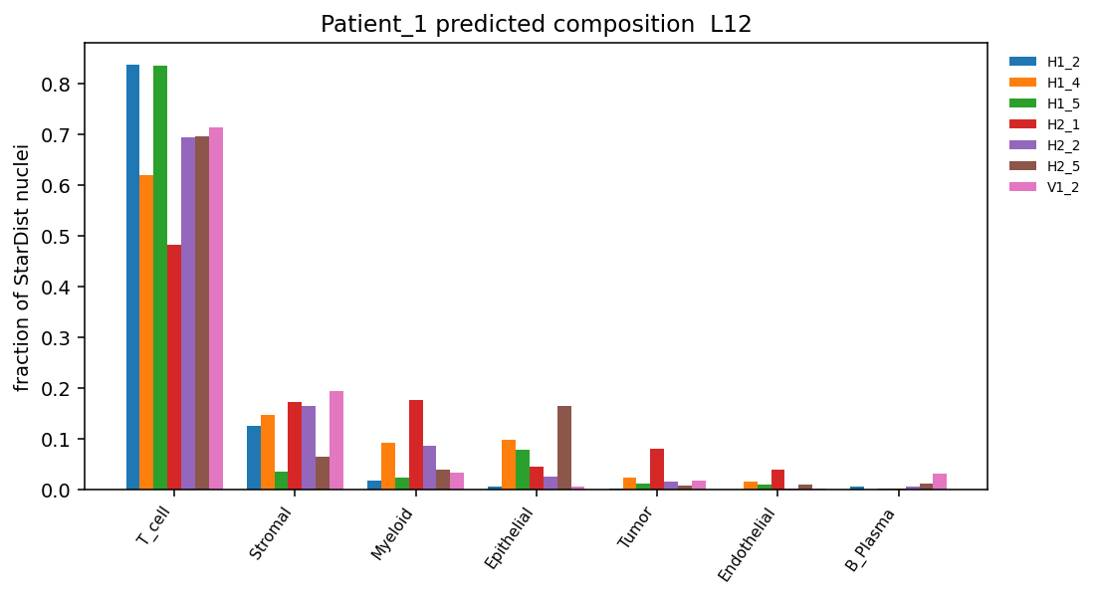

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1_composition_L12.png

===== Patient_1 L2 =====


fraction                                            \
section               H1_2   H1_4   H1_5   H2_1   H2_2   H2_5   V1_2   
class                                                                  
B_cell               0.569  0.138  0.142  0.104  0.403  0.435  0.466   
CD4_T                0.154  0.301  0.562  0.195  0.113  0.123  0.093   
Fibroblast           0.188  0.138  0.050  0.128  0.258  0.088  0.327   
Epithelial           0.010  0.118  0.071  0.080  0.031  0.177  0.011   
Endothelial          0.007  0.086  0.043  0.168  0.019  0.034  0.010   
CD8_T                0.052  0.104  0.069  0.114  0.078  0.082  0.032   
Tumor                0.004  0.031  0.014  0.099  0.029  0.010  0.026   
Macrophage           0.003  0.034  0.002  0.070  0.012  0.003  0.003   
Neutrophil           0.009  0.002  0.001  0.003  0.038  0.005  0.021   
DC                   0.001  0.025  0.028  0.012  0.008  0.034  0.001   
Injury_epithelial    0.000  0.008  0.014  0.001  0.000  0.004  0.000   
Stromal              0.002  0.008  0.001  0.014  0.002  0.002  0.000   
Plasma               0.000  0.007  0.002  0.012  0.000  0.001  0.000   
Tregs                0.001  0.000  0.000  0.000  0.008  0.002  0.011   
Myofibroblast          NaN  0.001  0.000  0.001    NaN  0.000    NaN   
Alveolar               NaN  0.000  0.001  0.000  0.000  0.000    NaN   
DCIS                 0.000  0.000  0.000  0.000  0.000  0.000  0.000   
NK                     NaN  0.000  0.000  0.000  0.000  0.000    NaN   
Myoepithelial          NaN  0.000  0.000  0.000  0.000  0.000  0.000   
Neural                 NaN  0.000    NaN  0.000    NaN  0.000    NaN   

                  mean_conf                ...                             n  \
section                H1_2   H1_4   H1_5  ...   H2_2   H2_5   V1_2     H1_2   
class                                      ...                                 
B_cell                0.449  0.322  0.342  ...  0.401  0.420  0.488  81156.0   
CD4_T                 0.328  0.296  0.326  ...  0.287  0.301  0.301  22020.0   
Fibroblast            0.313  0.263  0.252  ...  0.304  0.291  0.329  26806.0   
Epithelial            0.460  0.371  0.346  ...  0.420  0.493  0.437   1402.0   
Endothelial           0.243  0.244  0.249  ...  0.236  0.268  0.237   1026.0   
CD8_T                 0.276  0.261  0.244  ...  0.266  0.279  0.267   7406.0   
Tumor                 0.322  0.337  0.306  ...  0.350  0.362  0.387    596.0   
Macrophage            0.211  0.217  0.195  ...  0.203  0.202  0.195    408.0   
Neutrophil            0.235  0.192  0.211  ...  0.239  0.221  0.243   1234.0   
DC                    0.267  0.236  0.247  ...  0.271  0.293  0.247    214.0   
Injury_epithelial     0.313  0.338  0.379  ...  0.365  0.423  0.347     11.0   
Stromal               0.277  0.367  0.284  ...  0.244  0.284  0.248    275.0   
Plasma                0.200  0.223  0.221  ...  0.201  0.208  0.186     12.0   
Tregs                 0.251  0.214  0.259  ...  0.253  0.248  0.275    177.0   
Myofibroblast           NaN  0.192  0.197  ...    NaN  0.219    NaN      NaN   
Alveolar                NaN  0.219  0.224  ...  0.156  0.176    NaN      NaN   
DCIS                  0.273  0.212  0.279  ...  0.326  0.294  0.341      5.0   
NK                      NaN  0.192  0.181  ...  0.150  0.212    NaN      NaN   
Myoepithelial           NaN  0.172  0.236  ...  0.225  0.203  0.289      NaN   
Neural                  NaN  0.161    NaN  ...    NaN  0.144    NaN      NaN   

                                                                           
section               H1_4      H1_5     H2_1     H2_2      H2_5     V1_2  
class                                                                      
B_cell             40747.0   48370.0  18463.0  73694.0  155818.0  75727.0  
CD4_T              88788.0  191850.0  34677.0  20634.0   44104.0  15026.0  
Fibroblast         40843.0   17008.0  22796.0  47259.0   31438.0  53040.0  
Epithelial         34866.0   24282.0  14177.0   5739.0   63499.0

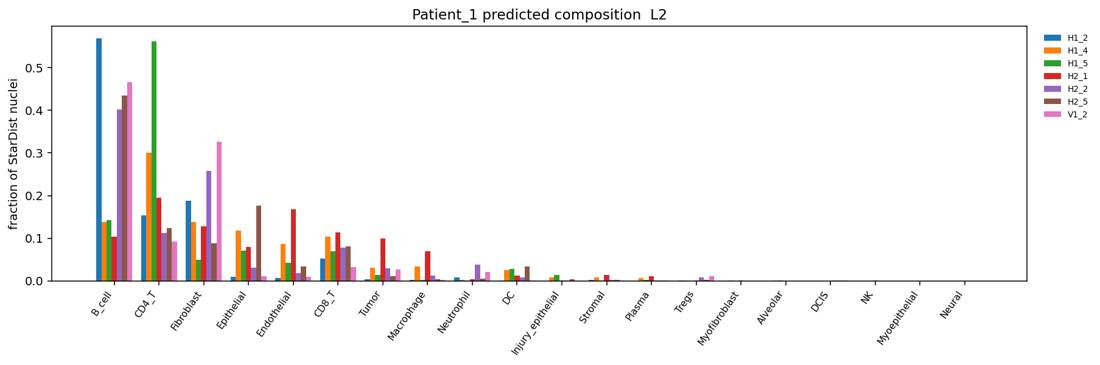

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1_composition_L2.png
Patient_1__H1_2


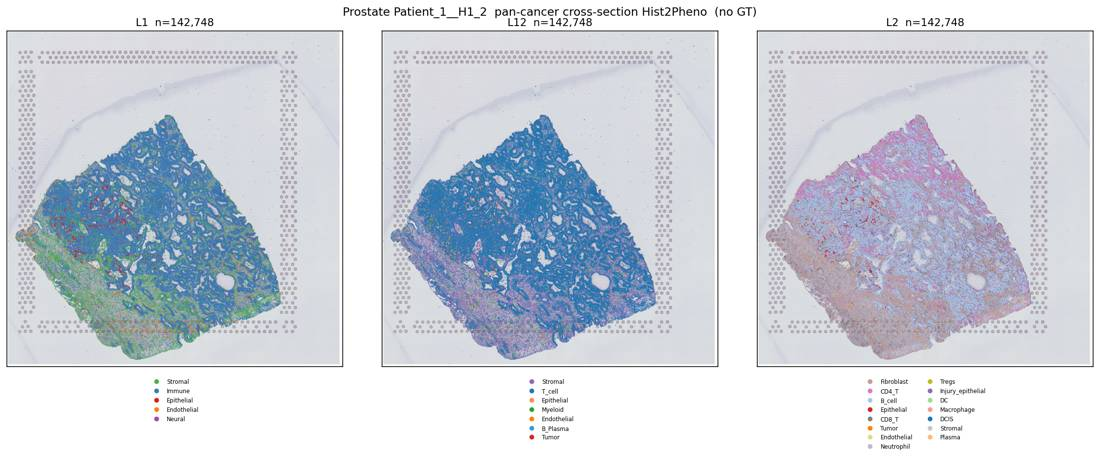

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_2_spatial_L1_L12_L2.png
Patient_1__H1_4


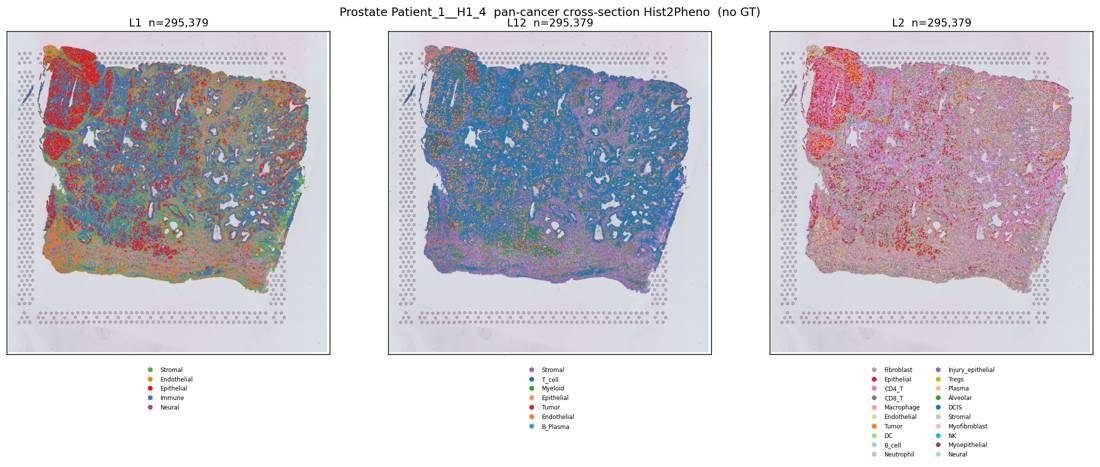

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_4_spatial_L1_L12_L2.png
Patient_1__H1_5


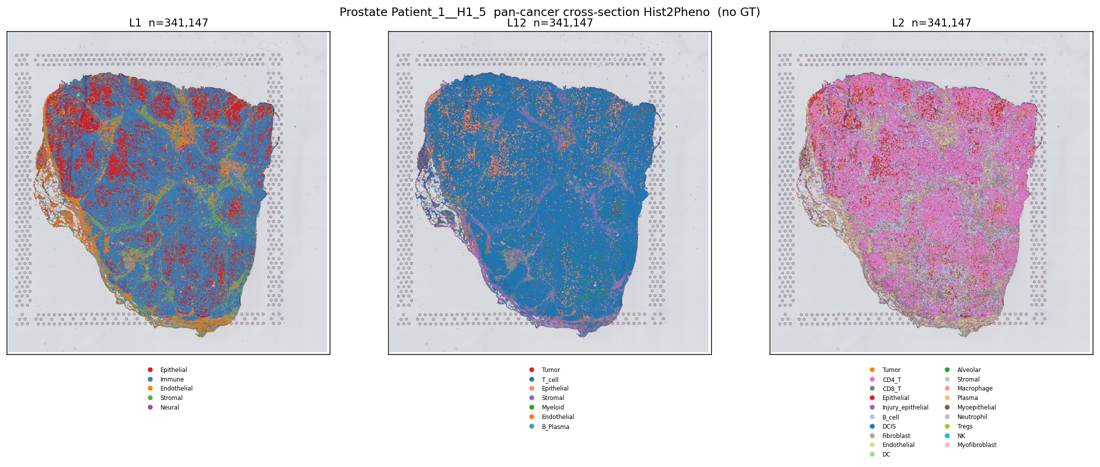

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_5_spatial_L1_L12_L2.png
Patient_1__H2_1


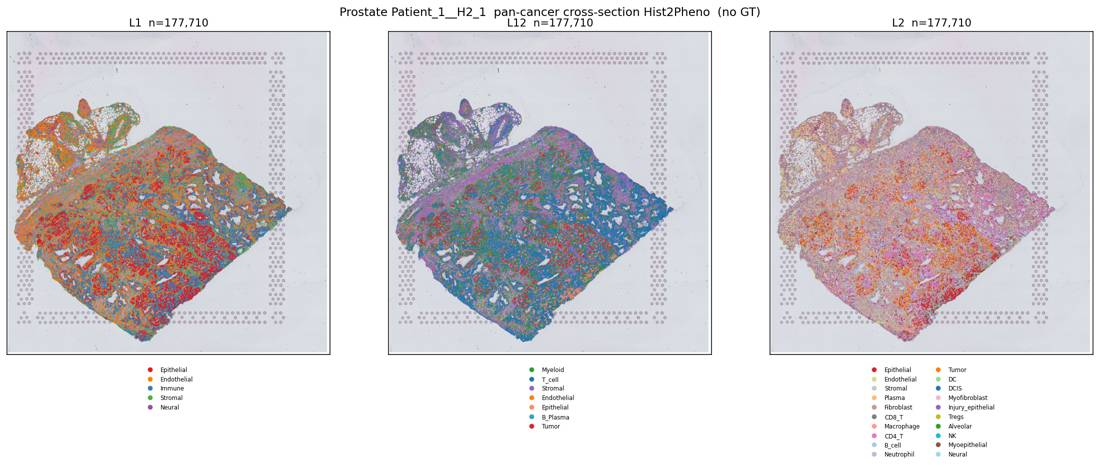

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_1_spatial_L1_L12_L2.png
Patient_1__H2_2


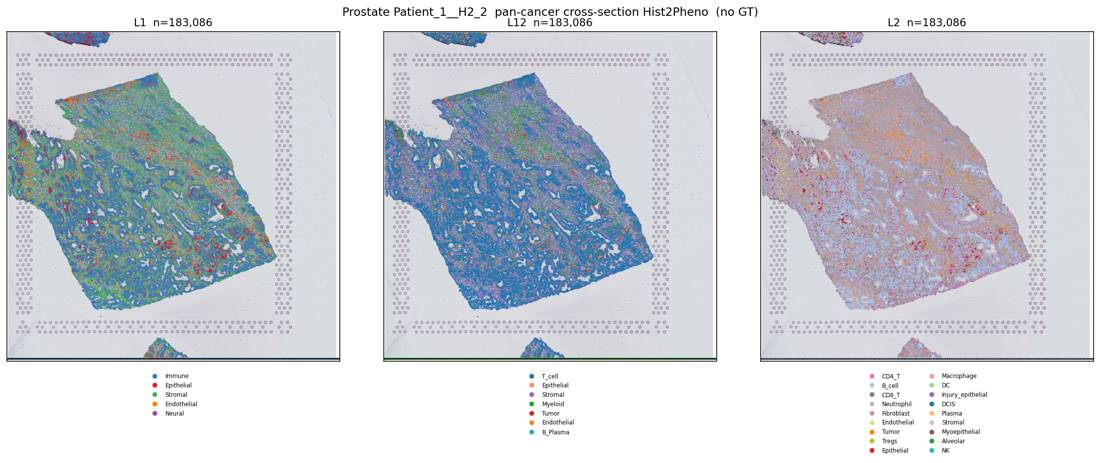

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_2_spatial_L1_L12_L2.png
Patient_1__H2_5


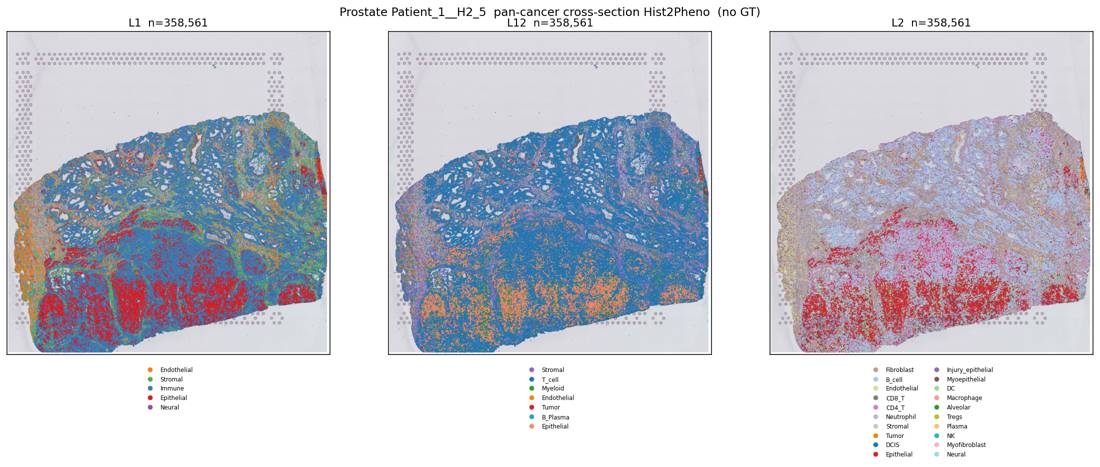

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_5_spatial_L1_L12_L2.png
Patient_1__V1_2


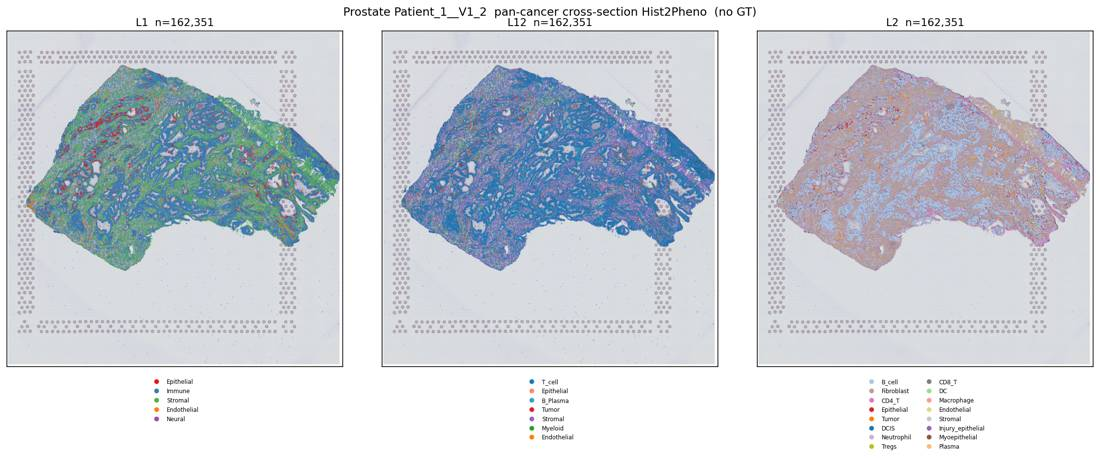

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__V1_2_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(s.split("__", 1)[-1] for s in missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/Prostate/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    sub["section"] = sub["sample"].str.split("__").str[-1]
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="section", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["section"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["section"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    if SAVE_FIGURES:
        out = fig_dir / f"{PATIENT}_composition_{head}.png"
        fig.savefig(out, dpi=DPI, bbox_inches="tight")
        print(out)
    display(fig)
    plt.close(fig)

for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** is converted with **that slide's** µm/px, not 0.5. TLS, SRI, and TNI each use a 1×3 row. Previews in this notebook are resized; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

PROSTATE_NICHE = OrganNicheConfig(
    pan_organ="pancancer_prostate",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="Prostate",
)
display(hni.index_formula_table(PROSTATE_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## Patient_1 — TLS / SRI / TNI

[niche] cache Patient_1__H1_2_niche_indices.h5ad  n=142,748  µm/px=0.6876
  TLS hotspot: {'n_cells_total': 142748, 'n_candidate_cells': 7138, 'fraction_candidate': 0.0500042032112534, 'max_tls_spatial': 0.2534694875568675, 'mean_tls_spatial_candidate': 0.203279156382899, 'centroid_x': 4849.088111603551, 'centroid_y': 7796.5942610767115}
  mean TLS=0.721  TLS_spatial=0.163  SRI=40.470  TNI=59.813
[niche] cache Patient_1__H1_4_niche_indices.h5ad  n=295,379  µm/px=0.5730
  TLS hotspot: {'n_cells_total': 295379, 'n_candidate_cells': 14769, 'fraction_candidate': 0.050000169274051307, 'max_tls_spatial': 0.23856966327077253, 'mean_tls_spatial_candidate': 0.20444758193862825, 'centroid_x': 7986.25998443866, 'centroid_y': 6283.62676252419}
  mean TLS=0.548  TLS_spatial=0.148  SRI=5.360  TNI=10.579
[niche] cache Patient_1__H1_5_niche_indices.h5ad  n=341,147  µm/px=0.6876
  TLS hotspot: {'n_cells_total': 341147, 'n_candidate_cells': 17058, 'fraction_candidate': 0.050001905336995486, 'max_tls_spat

,sample,section,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,Patient_1__H1_2,H1_2,142748,0.721,0.786,0.966,0.994,0.163,0.170,0.195,0.253,0.652,0.524,0.019,0.037,0.172,0.828
1,Patient_1__H1_4,H1_4,295379,0.548,0.553,0.894,0.987,0.148,0.153,0.196,0.239,0.604,0.602,0.109,0.197,0.180,0.773
2,Patient_1__H1_5,H1_5,341147,0.678,0.726,0.916,0.984,0.185,0.192,0.230,0.272,0.592,0.548,0.068,0.128,0.209,0.823
3,Patient_1__H2_1,H2_1,177710,0.461,0.437,0.840,0.978,0.125,0.123,0.184,0.245,0.632,0.628,0.160,0.275,0.167,0.733
4,Patient_1__H2_2,H2_2,183086,0.599,0.621,0.936,0.991,0.152,0.160,0.202,0.275,0.665,0.651,0.046,0.089,0.178,0.789
5,Patient_1__H2_5,H2_5,358561,0.642,0.705,0.947,0.995,0.165,0.168,0.222,0.275,0.512,0.464,0.016,0.032,0.176,0.795
6,Patient_1__V1_2,V1_2,162351,0.626,0.635,0.972,0.996,0.140,0.142,0.175,0.262,0.518,0.500,0.010,0.020,0.141,0.786


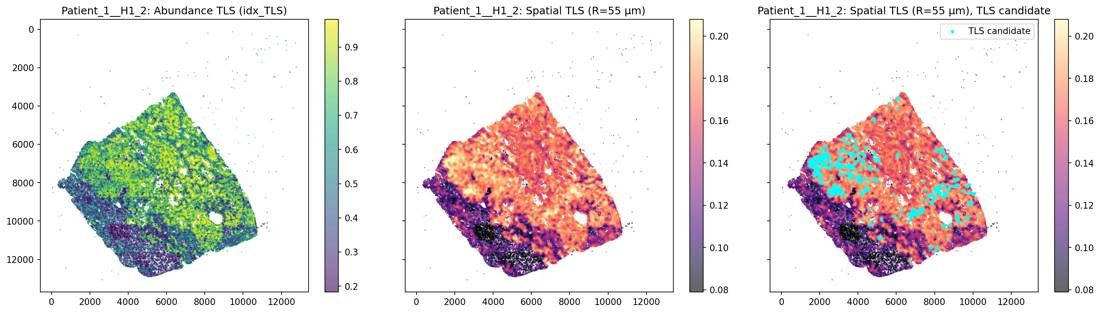

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_2_TLS_abundance_vs_spatial.png


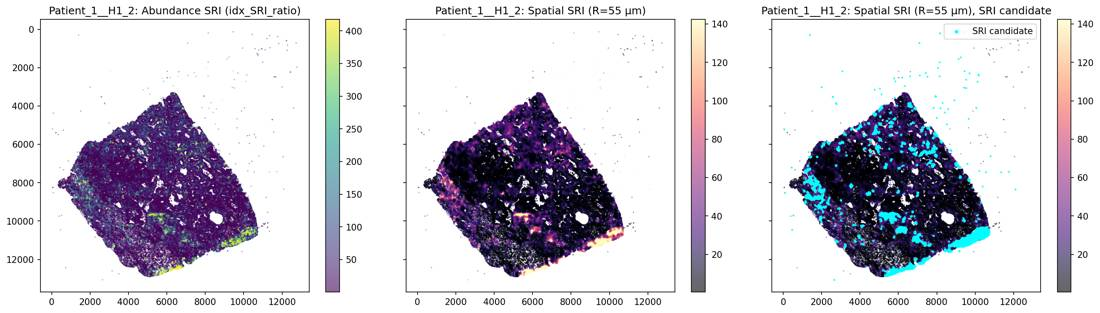

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_2_SRI_abundance_vs_spatial.png


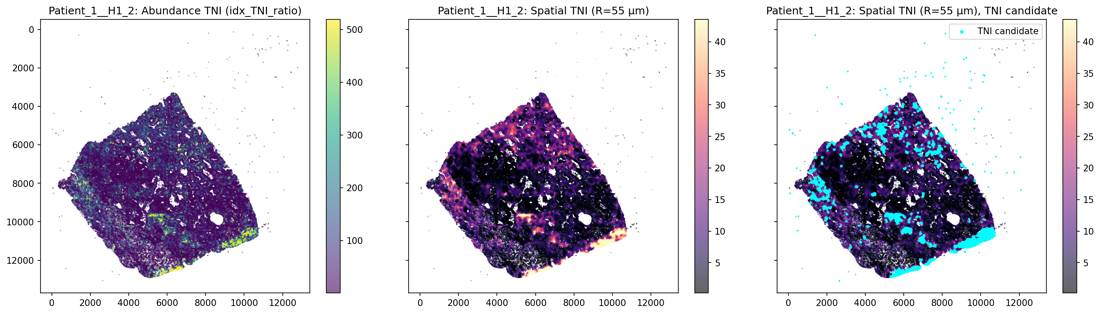

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_2_TNI_abundance_vs_spatial.png


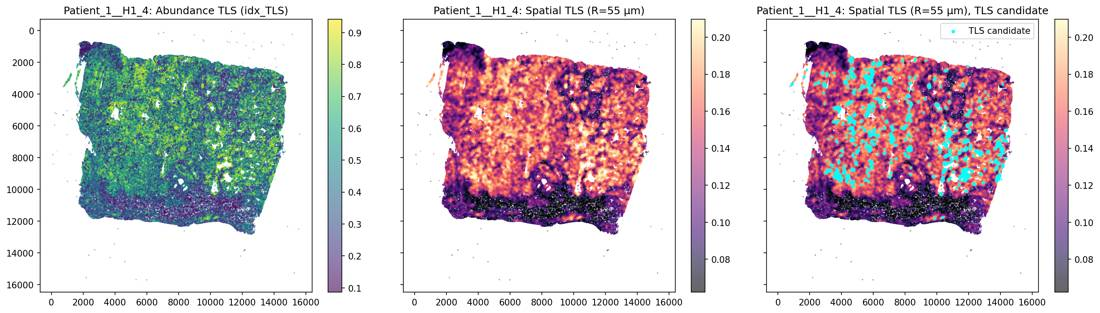

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_4_TLS_abundance_vs_spatial.png


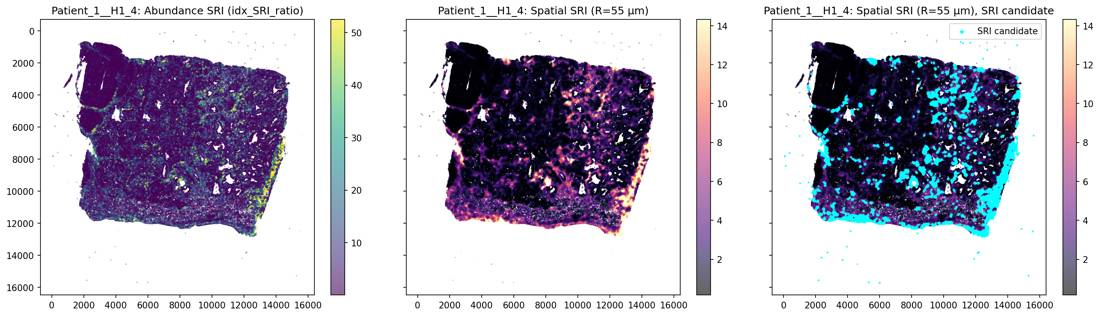

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_4_SRI_abundance_vs_spatial.png


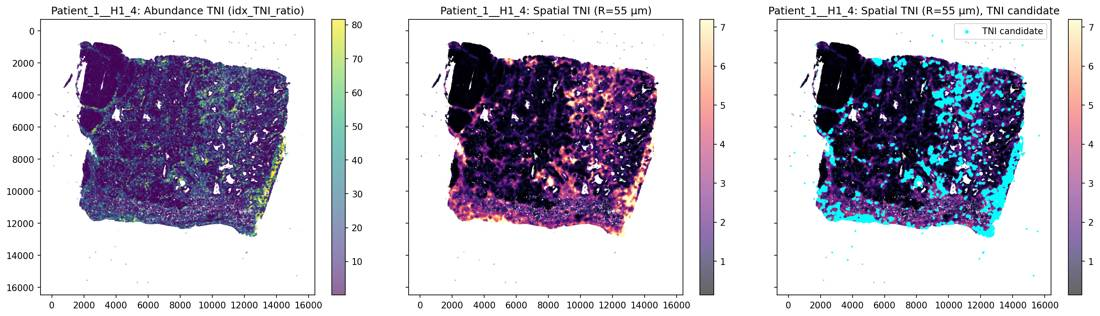

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_4_TNI_abundance_vs_spatial.png


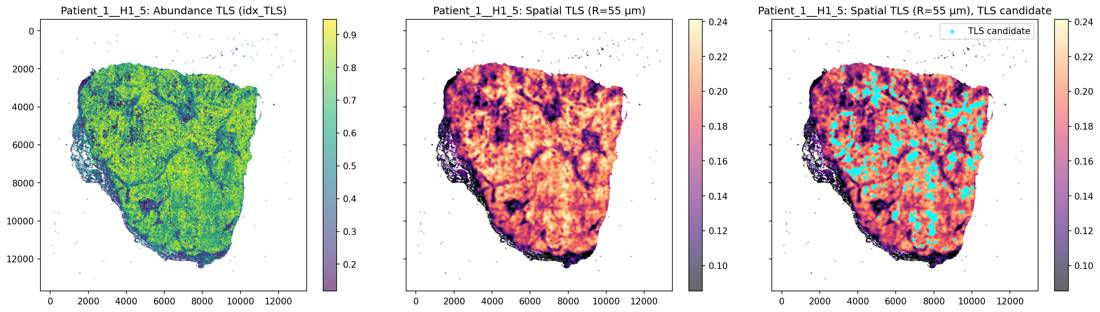

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_5_TLS_abundance_vs_spatial.png


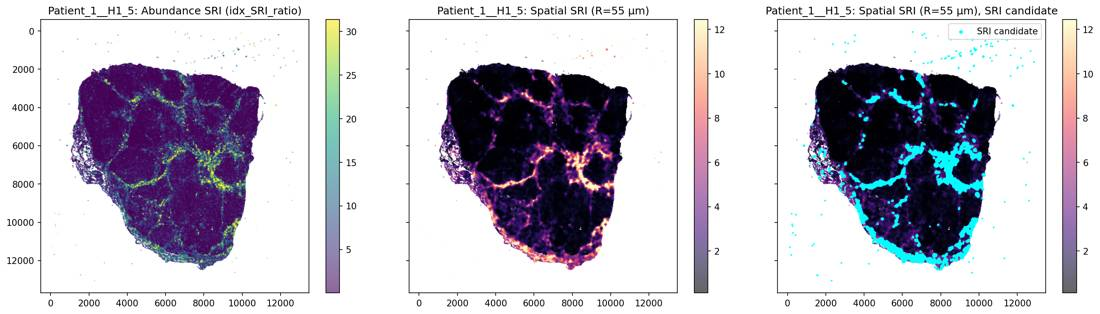

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_5_SRI_abundance_vs_spatial.png


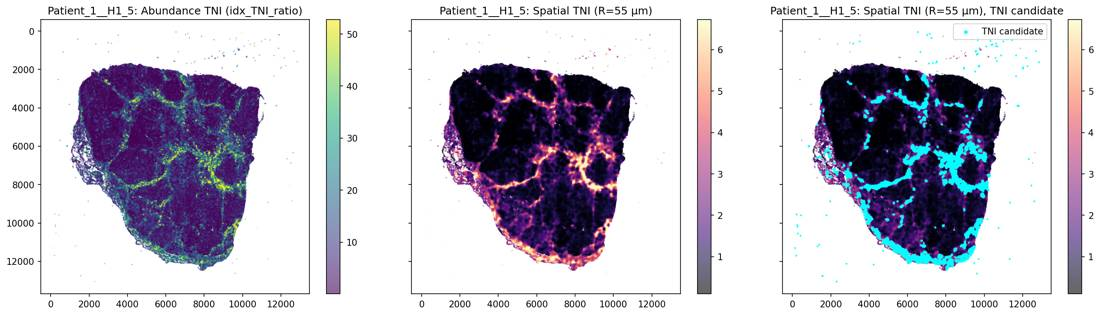

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_5_TNI_abundance_vs_spatial.png


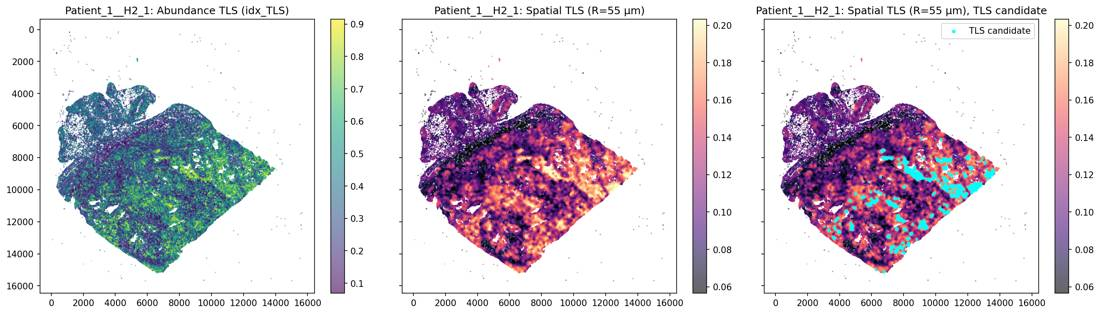

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_1_TLS_abundance_vs_spatial.png


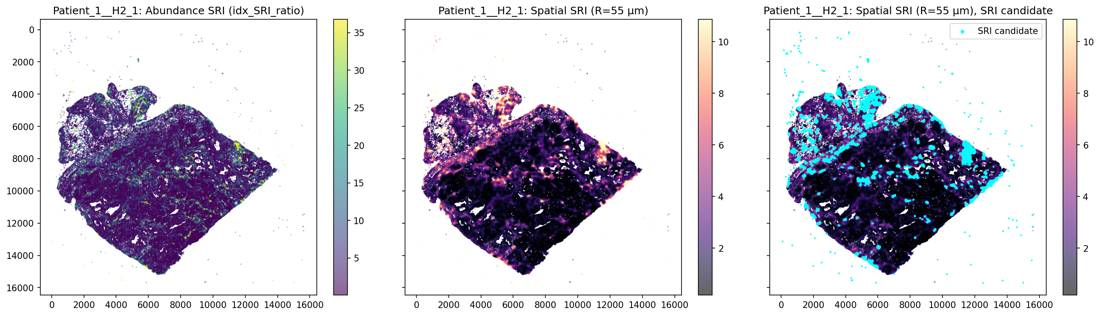

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_1_SRI_abundance_vs_spatial.png


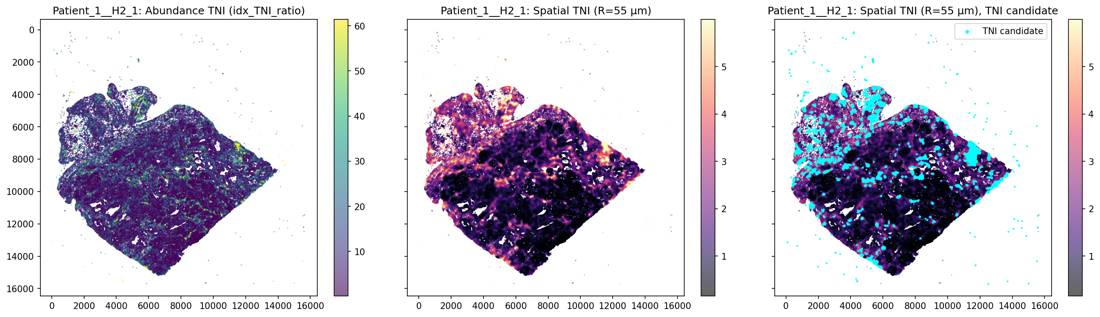

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_1_TNI_abundance_vs_spatial.png


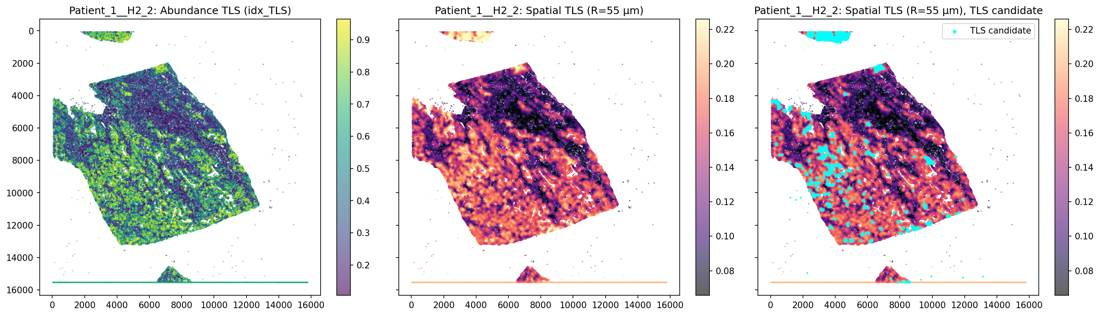

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_2_TLS_abundance_vs_spatial.png


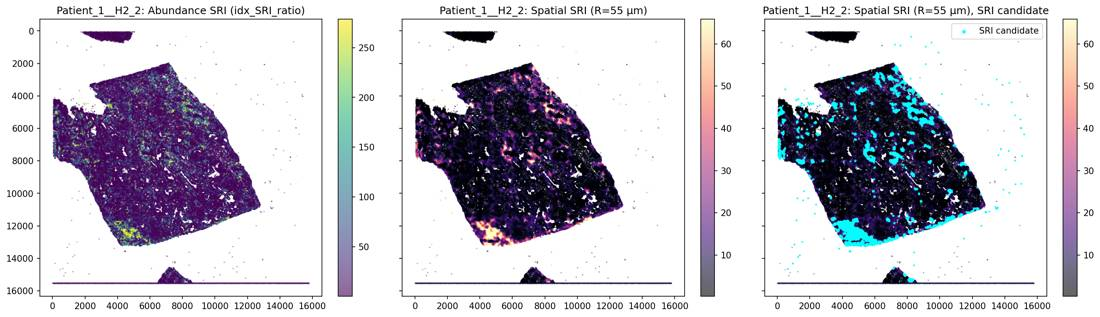

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_2_SRI_abundance_vs_spatial.png


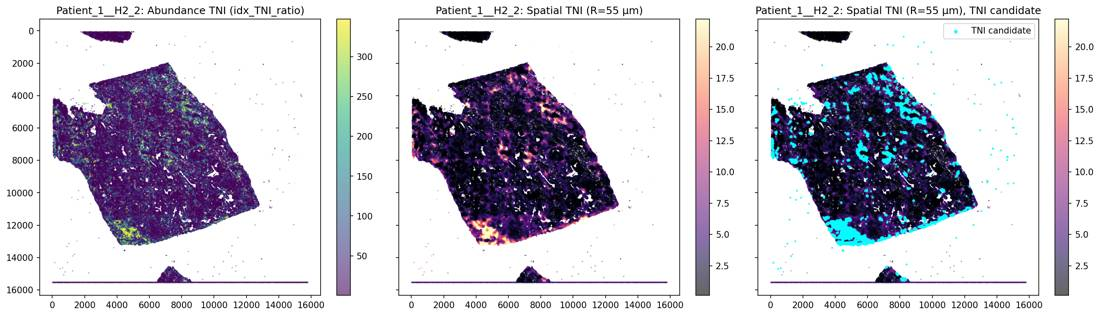

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_2_TNI_abundance_vs_spatial.png


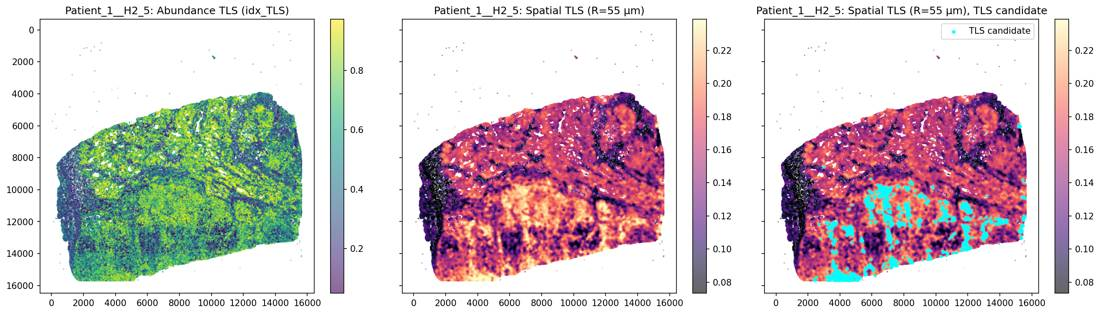

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_5_TLS_abundance_vs_spatial.png


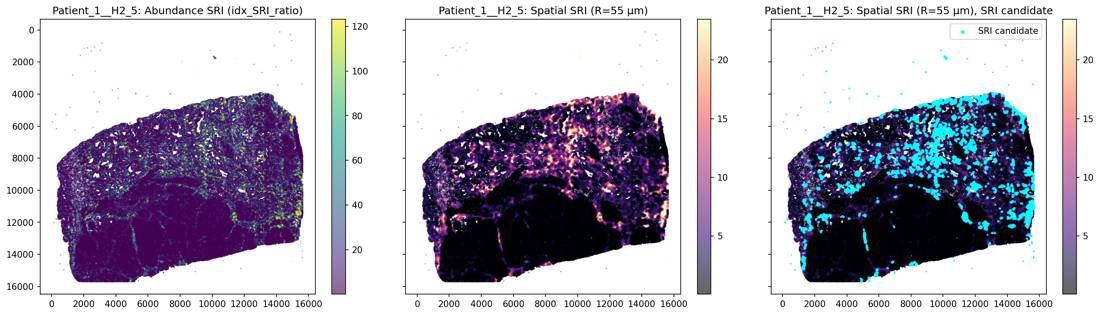

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_5_SRI_abundance_vs_spatial.png


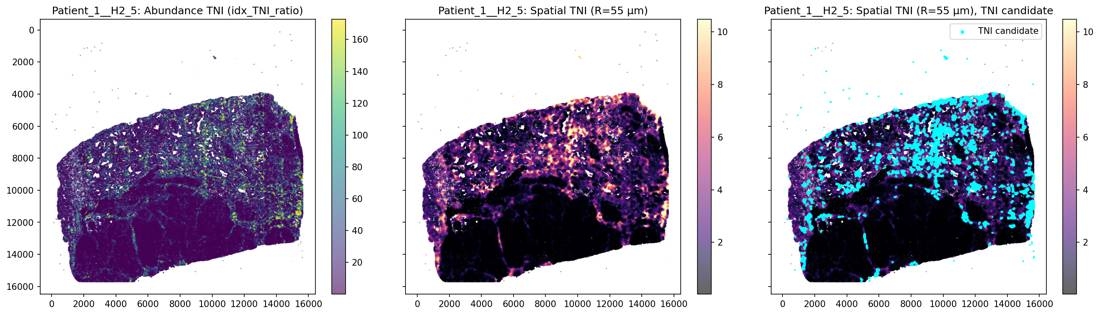

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__H2_5_TNI_abundance_vs_spatial.png


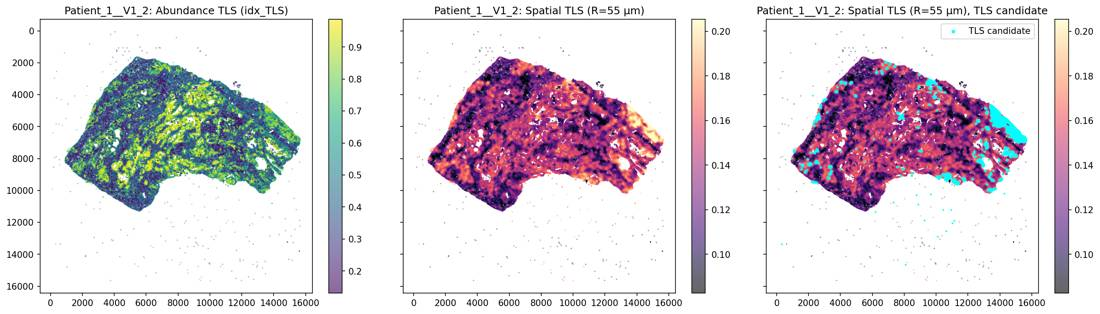

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__V1_2_TLS_abundance_vs_spatial.png


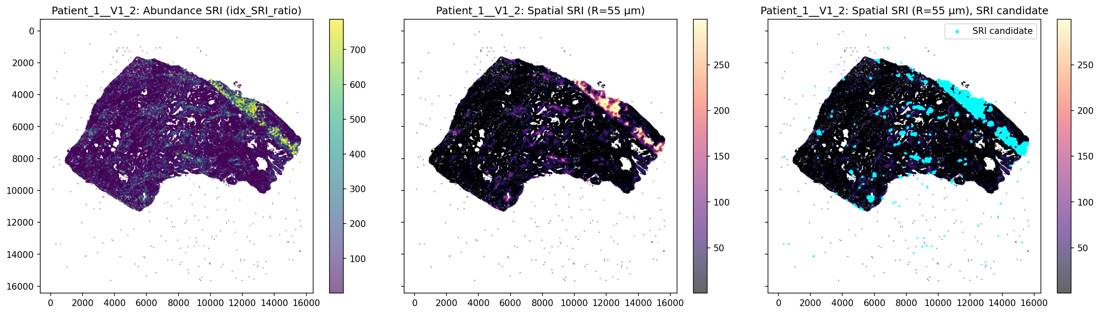

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__V1_2_SRI_abundance_vs_spatial.png


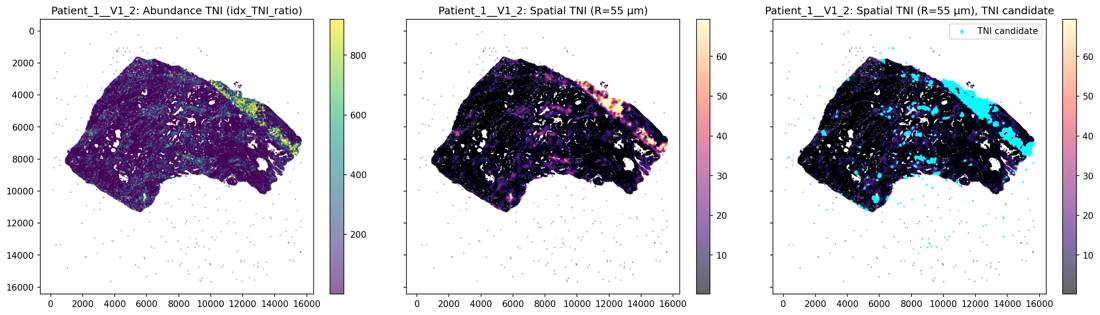

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/Prostate/pred_pancancer_section/figures/Patient_1__V1_2_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(s.split("__", 1)[-1] for s in missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/Prostate/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, PROSTATE_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, PROSTATE_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, PROSTATE_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant.insert(1, "section", tls_quant["sample"].str.split("__").str[-1])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
